# Setup

In [1]:
install_if_missing <- function(pkg) {
  if (!requireNamespace(pkg, quietly = TRUE)) {
    install.packages(pkg)
  }
  suppressPackageStartupMessages(library(pkg, character.only = TRUE))
}

packages <- c(
  "viridis",
  "ggthemes",
  "scales",
  "skimr",
  "lubridate",
  "tidyverse",
  "bigrquery",
  "data.table",
  "dplyr",
  "tidyr",
  "purrr",
  "broom",
  "mcca",
  "pheatmap",
  "binom"
)

invisible(lapply(packages, install_if_missing))

## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}



Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done

Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done



## Load and merge data

In [2]:
current_directory <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48"
output_dir <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data"

#Load demographic data
demo_file = paste0(current_directory, "/data/Demographic_and_ancestry_covariates.csv")
demo  <- read_csv(demo_file) |> 
    select(-c(income, education)) |> 
    rename(age = age_at_last_event)

#Load SES data
ses_file = paste0(current_directory, "/data/SES_data.csv")
ses_data  <- read_csv(ses_file)

#MERGE
demo_sdoh<-merge(demo, ses_data, on="person_id", how="inner")

#Load PRS data
PRS_file = paste0(current_directory, "/data/adjusted_PRS_scores.csv")
PRS  <- read_csv(PRS_file) 

#Load Case control info 
name_of_file_in_bucket <- 'Case_Control_df.csv'
system(paste0("gsutil cp gs://rw-migration-aou-rw-55feedb6/notebooks/Case_Control_df.csv ."), intern=T)
case_control  <- read_csv(name_of_file_in_bucket)

merged_data<-merge(PRS, case_control, on="person_id", how="left")
merged_data_0<-merge(merged_data, demo_sdoh, on="person_id", how="left")

dim(merged_data)

#Load PsRS data 
PsRS_file = paste0(current_directory, "/data/individual_PsRS_OOF.csv")
PsRS  <- read_csv(PsRS_file)

#MERGE
merged_data<-merge(merged_data_0, PsRS, on="person_id", how="left")
colnames(merged_data)

Rows: 135557 Columns: 51
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (9): SexGender, ancestry_pred, education, where_born, military, health...
dbl  (30): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (8): AIAN, Asian, Black, Mid, Multiple, PI, White, His
dttm  (1): basics_survey_datetime
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 214915 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (13): person_id, income, education, per_poverty_threshold, individual_po...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 135557 Columns: 9
── Column specification ────────────────────

character(0)

Rows: 265954 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] 135033     18

Rows: 104438 Columns: 9
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (9): person_id, Asthma_PsRS, Afib_PsRS, BreastC_PsRS, CKD_PsRS, CHD_PsRS...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "person_id"                         "Asthma_adjusted_score"            
 [3] "Afib_adjusted_score"               "BreastC_adjusted_score"           
 [5] "CKD_adjusted_score"                "CHD_adjusted_score"               
 [7] "ProstateC_adjusted_score"          "t1d_adjusted_score"               
 [9] "t2d_adjusted_score"                "Asthma"                           
[11] "Afib"                              "BreastC"                          
[13] "CKD"                               "CHD"                              
[15] "HyperC"                            "ProstateC"                        
[17] "t2d"                               "t1d"                              
[19] "date_of_birth"                     "AIAN"                             
[21] "Asian"                             "Black"                            
[23] "Mid"                               "Multiple"                         
[25] "PI"                                "White"                            
[27] "His"                               "race_unknown"                     
[29] "SexGender"                         "age_today"                        
[31] "ancestry_pred"                     "PC_1"                             
[33] "PC_2"                              "PC_3"                             
[35] "PC_4"                              "PC_5"                             
[37] "PC_6"                              "PC_7"                             
[39] "PC_8"                              "PC_9"                             
[41] "PC_10"                             "PC_11"                            
[43] "PC_12"                             "PC_13"                            
[45] "PC_14"                             "PC_15"                            
[47] "PC_16"                             "number_living"                    
[49] "where_born"                        "military"                         
[51] "healthcare"                        "disabled"                         
[53] "sexual_orientation"                "LGBTQIA"                          
[55] "basics_survey_datetime"            "income_grouped"                   
[57] "min_date"                          "max_date"                         
[59] "ehr_length"                        "relative_health"                  
[61] "record_depth"                      "visit_frequency"                  
[63] "age"                               "record_depth_winsorized"          
[65] "visit_frequency_winsorized"        "age2"                             
[67] "income"                            "education"                        
[69] "per_poverty_threshold"             "individual_poverty"               
[71] "american_community_survey_year"    "fraction_assisted_income"         
[73] "fraction_no_high_school_education" "lower_median_income"              
[75] "fraction_no_health_insurance"      "fraction_poverty"                 
[77] "fraction_vacant_housing"           "deprivation_index"                
[79] "Asthma_PsRS"                       "Afib_PsRS"                        
[81] "BreastC_PsRS"                      "CKD_PsRS"                         
[83] "CHD_PsRS"                          "ProstateC_PsRS"                   
[85] "t2d_PsRS"                          "t1d_PsRS"

In [3]:
merged_data <- merged_data %>%
  mutate(
    SexGenderCis_male = ifelse(SexGender == "Cis_male", 1, 0),
    SexGenderCis_female = ifelse(SexGender == "Cis_female", 1, 0),
    SexGenderSGM = ifelse(SexGender == "SGM", 1, 0)
  )

## Set up lists

In [4]:
diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "ProstateC", "t2d", "t1d")


disease_name_mapping <- c(
  "Asthma" = "Asthma",
    "Afib" = "Atrial Fibrilation (Afib)",
    "BreastC" = "Breast Cancer",
    "CKD" = "Chronic Kidney Disease (CKD)", 
    "CHD" = "Coronary Heart Disease (CHD)",
    "ProstateC" = "Prostate Cancer", 
  "t2d" = "Type 2 Diabetes (T2D)",
  "t1d" = "Type 1 Diabetes (T1D)"
)

disease_name_mapping_short <- c(
    "Afib" = "Afib",
    "CKD" = "CKD", 
    "CHD" = "CHD",
  "t2d" = "T2D",
  "t1d" = "T1D",
    "BreastC" = "Breast\nCancer",
    "ProstateC" = "Prostate\nCancer"
)

facet_order <- c(
  "Breast\nCancer", "Prostate\nCancer", "Afib", "T2D",
  "CKD", "CHD", "Asthma", "T1D"
)

## Min-max normalize for comparability

In [5]:
merged_data <- merged_data %>%
  mutate(
    across(
      matches("(_adjusted_score|_PsRS)$"),   # columns ending with either pattern
      ~ (.-min(., na.rm = TRUE)) / (max(., na.rm = TRUE) - min(., na.rm = TRUE))
    )
  )


## Make Genetic Risk Quantiles

In [6]:
merged_data <- merged_data %>%
  mutate(
    across(
      ends_with("_adjusted_score"),
      ~ ntile(.x, 10),
      .names = "{sub('_adjusted_score$', '', .col)}_quantiles"
    )
  )


## Of those top 10% genetic risk, how much of that explained by SDoH?

In [7]:
plot_df <- map_dfr(diseases, function(disease) {

  q_col    <- paste0(disease, "_quantiles")
  psrs_col <- paste0(disease, "_PsRS")

  base <- merged_data %>%
    filter(.data[[q_col]] == 10) %>%
    mutate(PsRS_q = ntile(.data[[psrs_col]], 5))

  summarize_group <- function(df, label) {
    df %>%
      summarise(
        cases = sum(.data[[disease]] == 1, na.rm = TRUE),
        n     = sum(!is.na(.data[[disease]])),
        prevalence = round(cases / n,4), 
      ) %>%
      mutate(
        ci = binom.confint(cases, n, method = "wilson"),
        lower = round(ci$lower, 3),
        upper = round(ci$upper, 3), 
        disease = disease,
        PsRS_group = label
      ) %>%
      select(disease, PsRS_group, prevalence, lower, upper)
  }

  bind_rows(
    summarize_group(base %>% filter(PsRS_q == 1),      "Low PsRS (Q1)"),
    summarize_group(base %>% filter(PsRS_q %in% 2:4),  "Mid PsRS (Q2–Q4)"),
    summarize_group(base %>% filter(PsRS_q == 5),      "High PsRS (Q5)")
  )
})

plot_df_top_genetic_risk <- plot_df %>% mutate(disease = as.character(disease), 
                              disease = recode(disease, !!!disease_name_mapping_short, .default = disease) )


plot_df_top_genetic_risk <- plot_df_top_genetic_risk %>%
  mutate(
    disease = factor(disease, levels = facet_order),
    PsRS_group = factor(
      PsRS_group,
      levels = c("Low PsRS (Q1)", "Mid PsRS (Q2–Q4)", "High PsRS (Q5)")
    )
  )


plot_df_top_genetic_risk

disease,PsRS_group,prevalence,lower,upper
<fct>,<fct>,<dbl>,<dbl>,<dbl>
Asthma,Low PsRS (Q1),0.3420,0.307,0.379
Asthma,Mid PsRS (Q2–Q4),0.4765,0.454,0.499
Asthma,High PsRS (Q5),0.7066,0.670,0.740
Afib,Low PsRS (Q1),0.2380,0.205,0.275
Afib,Mid PsRS (Q2–Q4),0.4543,0.431,0.478
Afib,High PsRS (Q5),0.5445,0.503,0.585
Breast Cancer,Low PsRS (Q1),0.0602,0.049,0.074
Breast Cancer,Mid PsRS (Q2–Q4),0.1193,0.110,0.130
Breast Cancer,High PsRS (Q5),0.1738,0.154,0.195


In [8]:
# Filter for only Low and High PsRS groups
diff_table_top_genetic_risk <- plot_df %>%
  filter(PsRS_group %in% c("Low PsRS (Q1)", "High PsRS (Q5)")) %>%
  select(disease, PsRS_group, prevalence) %>%
  pivot_wider(
    names_from = PsRS_group,
    values_from = prevalence
  ) %>%
  mutate(
    percent_difference = round(100 * (`High PsRS (Q5)` - `Low PsRS (Q1)`) / `Low PsRS (Q1)`,2)
  ) %>%
  select(disease, `Low PsRS (Q1)`, `High PsRS (Q5)`, percent_difference)

diff_table_top_genetic_risk


disease,Low PsRS (Q1),High PsRS (Q5),percent_difference
<chr>,<dbl>,<dbl>,<dbl>
Asthma,0.3420,0.7066,106.61
Afib,0.2380,0.5445,128.78
BreastC,0.0602,0.1738,188.70
CKD,0.3342,0.3608,7.96
CHD,0.1713,0.2558,49.33
ProstateC,0.2984,0.8178,174.06
t2d,0.3964,0.6693,68.84
t1d,0.0350,0.0607,73.43


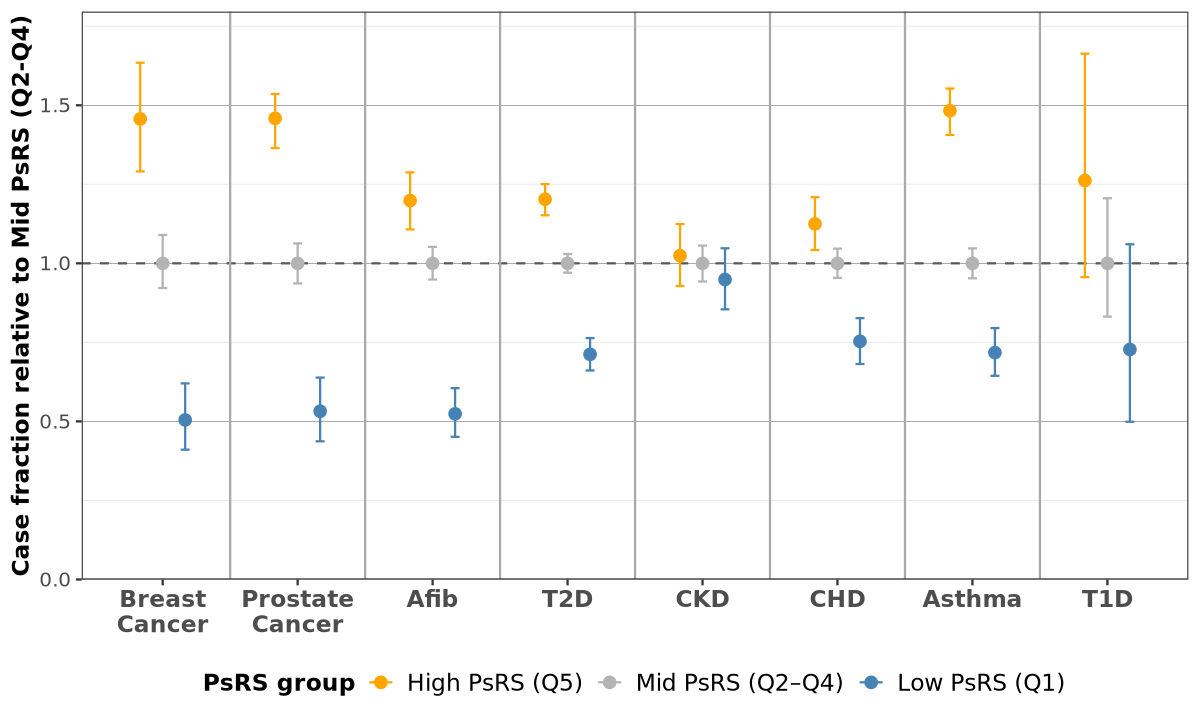

In [12]:
options(repr.plot.width = 10, repr.plot.height = 6)  # Set width and height

plot_df_relative <- plot_df %>%
  group_by(disease) %>%
  mutate(
    mid_prevalence = prevalence[PsRS_group == "Mid PsRS (Q2–Q4)"][1],
    relative_prevalence = prevalence / mid_prevalence,
    relative_lower = lower / mid_prevalence,
    relative_upper = upper / mid_prevalence
  ) %>%
  ungroup()

plot_df_relative <- plot_df_relative  %>% mutate(disease = as.character(disease), 
                                                    disease = recode(disease, 
                                                    !!!disease_name_mapping_short, 
                                                                     .default = disease),
                                                    disease = factor(disease, levels = facet_order),
)

write_excel_csv(plot_df_relative, file.path(output_dir, "relative_PsRS_risk_top_genetic_risk_decile.csv"))

final_A_plot <- ggplot(plot_df_relative, aes(
  x = disease,
  y = relative_prevalence,
  color = fct_relevel(PsRS_group, "High PsRS (Q5)", "Mid PsRS (Q2–Q4)", "Low PsRS (Q1)")
)) +
  geom_hline(yintercept = 1, linetype = "dashed", color = "grey35") +
  geom_point(
    position = position_dodge(width = 0.5),
    size = 3
  ) +
  scale_y_continuous(
    limits = c(0, NA),
    expand = expansion(mult = c(0, 0.08))
  ) +
  geom_errorbar(
    aes(ymin = relative_lower, ymax = relative_upper),
    position = position_dodge(width = 0.5),
    width = 0.2
  ) +
  scale_color_manual(
    values = c(
      "Low PsRS (Q1)" = "steelblue",   
      "Mid PsRS (Q2–Q4)" = "grey70", 
      "High PsRS (Q5)" = "orange"   
    )
  ) +
  theme(
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(size = 0.1, color = "black"),
    axis.text.x = element_text(face="bold", size=14),
    axis.text.y = element_text(size=12),
    axis.title.y = element_text(face="bold", size=14),
    legend.title = element_text(face="bold", hjust = 0.5, size = 14),
    legend.text = element_text(size = 14),
    legend.position = "bottom",
    legend.box.spacing = unit(-5, "pt"),
  ) +
  labs(
    x = "",
    y = "Case fraction relative to Mid PsRS (Q2-Q4)",
    color = "PsRS group"
  ) +
  geom_vline(
    xintercept = seq(1.5, length(unique(plot_df_relative$disease)) - 0.5, 1),
    color = "darkgrey"
  )


final_A_plot

## Of those bottom 10% genetic risk, how much of that explained by SDoH?

In [13]:
plot_df <- map_dfr(diseases, function(disease) {

  q_col    <- paste0(disease, "_quantiles")
  psrs_col <- paste0(disease, "_PsRS")

  base <- merged_data %>%
    filter(.data[[q_col]] == 1) %>%
    mutate(PsRS_q = ntile(.data[[psrs_col]], 5))

  summarize_group <- function(df, label) {
    df %>%
      summarise(
        cases = sum(.data[[disease]] == 1, na.rm = TRUE),
        n     = sum(!is.na(.data[[disease]])),
        prevalence = round(cases / n,4), 
      ) %>%
      mutate(
        ci = binom.confint(cases, n, method = "wilson"),
        lower = round(ci$lower, 3),
        upper = round(ci$upper, 3), 
        disease = disease,
        PsRS_group = label
      ) %>%
      select(disease, PsRS_group, prevalence, lower, upper)
  }

  bind_rows(
    summarize_group(base %>% filter(PsRS_q == 1),      "Low PsRS (Q1)"),
    summarize_group(base %>% filter(PsRS_q %in% 2:4),  "Mid PsRS (Q2–Q4)"),
    summarize_group(base %>% filter(PsRS_q == 5),      "High PsRS (Q5)")
  )
})

plot_df_bottom_genetic_risk <- plot_df %>% mutate(disease = as.character(disease), 
                              disease = recode(disease, !!!disease_name_mapping_short, .default = disease) )


plot_df_bottom_genetic_risk <- plot_df_bottom_genetic_risk %>%
  mutate(
    disease = factor(disease, levels = facet_order),
    PsRS_group = factor(
      PsRS_group,
      levels = c("Low PsRS (Q1)", "Mid PsRS (Q2–Q4)", "High PsRS (Q5)")
    )
  )


plot_df_bottom_genetic_risk

disease,PsRS_group,prevalence,lower,upper
<fct>,<fct>,<dbl>,<dbl>,<dbl>
Asthma,Low PsRS (Q1),0.1948,0.164,0.229
Asthma,Mid PsRS (Q2–Q4),0.3132,0.292,0.336
Asthma,High PsRS (Q5),0.4930,0.452,0.534
Afib,Low PsRS (Q1),0.1336,0.106,0.166
Afib,Mid PsRS (Q2–Q4),0.2676,0.246,0.291
Afib,High PsRS (Q5),0.2414,0.206,0.281
Breast Cancer,Low PsRS (Q1),0.0314,0.023,0.042
Breast Cancer,Mid PsRS (Q2–Q4),0.0471,0.041,0.054
Breast Cancer,High PsRS (Q5),0.0744,0.061,0.090


In [14]:
plot_df_bottom_genetic_risk$PRS_decile <- 1
plot_df_top_genetic_risk$PRS_decile <- 10
plot_df_genetic_risk<-rbind(plot_df_top_genetic_risk, plot_df_bottom_genetic_risk) 
write_excel_csv(plot_df_genetic_risk, file.path(output_dir, "plot_df_genetic_risk_deciles.csv"))

In [15]:
# Filter for only Low and High PsRS groups
diff_table_bottom_genetic_risk <- plot_df %>%
  filter(PsRS_group %in% c("Low PsRS (Q1)", "High PsRS (Q5)")) %>%
  select(disease, PsRS_group, prevalence) %>%
  pivot_wider(
    names_from = PsRS_group,
    values_from = prevalence
  ) %>%
  mutate(
    percent_difference = round(100 * (`High PsRS (Q5)` - `Low PsRS (Q1)`) / `Low PsRS (Q1)`,2)
  ) %>%
  select(disease, `Low PsRS (Q1)`, `High PsRS (Q5)`, percent_difference)

diff_table_bottom_genetic_risk


disease,Low PsRS (Q1),High PsRS (Q5),percent_difference
<chr>,<dbl>,<dbl>,<dbl>
Asthma,0.1948,0.4930,153.08
Afib,0.1336,0.2414,80.69
BreastC,0.0314,0.0744,136.94
CKD,0.0949,0.2134,124.87
CHD,0.0708,0.1286,81.64
ProstateC,0.0855,0.4238,395.67
t2d,0.0564,0.3001,432.09
t1d,0.0069,0.0413,498.55


In [16]:
diff_table_bottom_genetic_risk$PRS_decile <- 1
diff_table_top_genetic_risk$PRS_decile <- 10
diff_table_genetic_risk<-rbind(diff_table_top_genetic_risk, diff_table_bottom_genetic_risk) 
write_excel_csv(diff_table_genetic_risk, file.path(output_dir, "diff_table_genetic_risk_deciles.csv"))

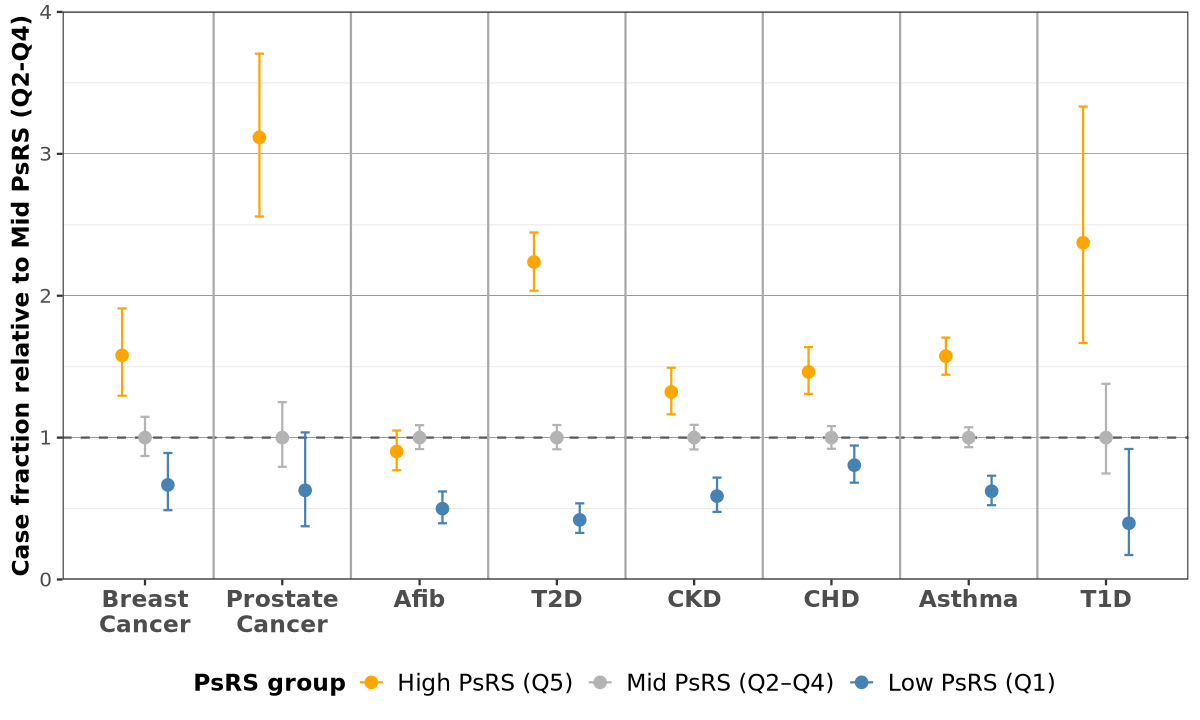

In [18]:
options(repr.plot.width = 10, repr.plot.height = 6)  # Set width and height

plot_df_relative <- plot_df %>%
  group_by(disease) %>%
  mutate(
    mid_prevalence = prevalence[PsRS_group == "Mid PsRS (Q2–Q4)"][1],
    relative_prevalence = prevalence / mid_prevalence,
    relative_lower = lower / mid_prevalence,
    relative_upper = upper / mid_prevalence
  ) %>%
  ungroup()

plot_df_relative <- plot_df_relative  %>% mutate(disease = as.character(disease), 
                                                    disease = recode(disease, 
                                                    !!!disease_name_mapping_short, 
                                                                     .default = disease),
                                                    disease = factor(disease, levels = facet_order),
)

write_excel_csv(plot_df_relative, file.path(output_dir, "relative_PsRS_risk_bottom_genetic_risk_decile.csv"))


final_B_plot <- ggplot(plot_df_relative, aes(
  x = disease,
  y = relative_prevalence,
  color = fct_relevel(PsRS_group, "High PsRS (Q5)", "Mid PsRS (Q2–Q4)", "Low PsRS (Q1)")
)) +
  geom_hline(yintercept = 1, linetype = "dashed", color = "grey35") +
  geom_point(
    position = position_dodge(width = 0.5),
    size = 3
  ) +
  scale_y_continuous(
    limits = c(0, NA),
    expand = expansion(mult = c(0, 0.08))
  ) +
  geom_errorbar(
    aes(ymin = relative_lower, ymax = relative_upper),
    position = position_dodge(width = 0.5),
    width = 0.2
  ) +
  scale_color_manual(
    values = c(
      "Low PsRS (Q1)" = "steelblue",   
      "Mid PsRS (Q2–Q4)" = "grey70", 
      "High PsRS (Q5)" = "orange"   
    )
  ) +
  theme(
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(size = 0.1, color = "black"),
    axis.text.x = element_text(face="bold", size=14),
    axis.text.y = element_text(size=12),
    axis.title.y = element_text(face="bold", size=14),
    legend.title = element_text(face="bold", hjust = 0.5, size = 14),
    legend.text = element_text(size = 14),
    legend.position = "bottom",
    legend.box.spacing = unit(-5, "pt"),
  ) +
  labs(
    x = "",
    y = "Case fraction relative to Mid PsRS (Q2-Q4)",
    color = "PsRS group"
  ) +
  geom_vline(
    xintercept = seq(1.5, length(unique(plot_df_relative$disease)) - 0.5, 1),
    color = "darkgrey"
  )


final_B_plot

In [ ]:
plot_df_relative

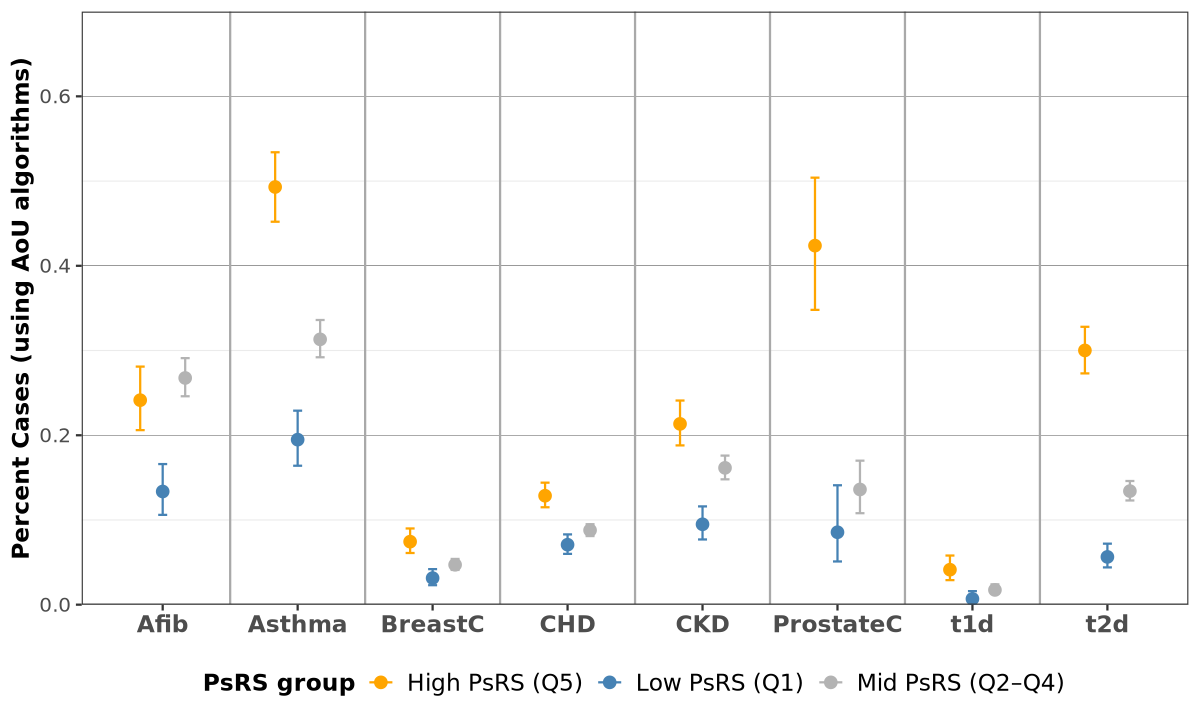

In [35]:
options(repr.plot.width = 10, repr.plot.height = 6)  # Set width and height

final_B_plot <- ggplot(plot_df, aes(
  x = disease,
  y = prevalence,
  color = PsRS_group
)) +
  geom_point(
    position = position_dodge(width = 0.5),
    size = 3
  ) +
  scale_y_continuous(
    limits = c(0, .70),
    expand = c(0, 0)
  ) +
  geom_errorbar(
    aes(ymin = lower, ymax = upper),
    position = position_dodge(width = 0.5),
    width = 0.2
  ) +
  scale_color_manual(
    values = c(
      "Low PsRS (Q1)" = "steelblue",   
      "Mid PsRS (Q2–Q4)" = "grey70", 
      "High PsRS (Q5)" = "orange"   
    )
  ) +
  theme(
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(size = 0.1, color = "black"),
    axis.text.x = element_text(face="bold", size=14),
    axis.text.y = element_text(size=12),
    axis.title.y = element_text(face="bold", size=14),
    legend.title = element_text(face="bold", hjust = 0.5, size = 14),
    legend.text = element_text(size = 14),
    legend.position = "bottom",
    legend.box.spacing = unit(-5, "pt"),
  ) +
  labs(
    x = "",
    y = "Percent Cases (using AoU algorithms)",
    color = "PsRS group"
  ) +
  geom_vline(
    xintercept = seq(1.5, length(unique(plot_df$disease)) - 0.5, 1),
    color = "darkgrey"
  )


final_B_plot

## Low genetic and High PsRS vs High genetic and Low PsRS

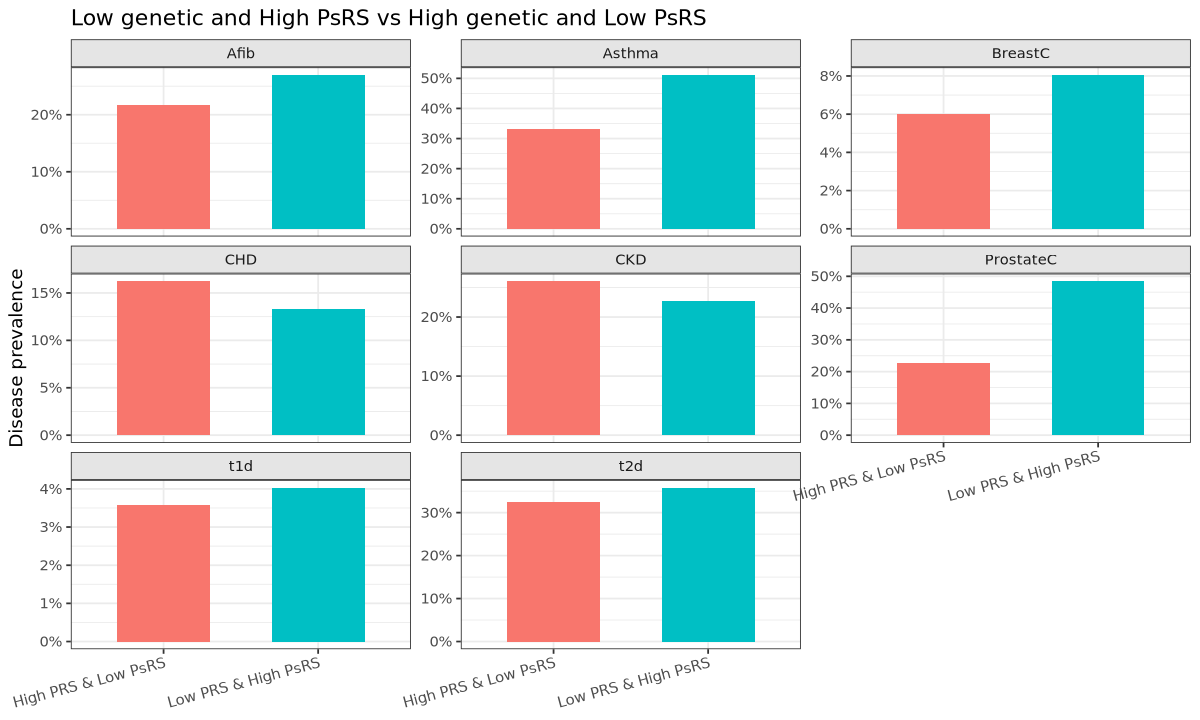

In [15]:
plot_df_2 <- map_dfr(diseases, function(disease) {

  q_col    <- paste0(disease, "_quantiles")
  psrs_col <- paste0(disease, "_PsRS")

  merged_data %>%
    mutate(PRS_q = ntile(.data[[q_col]], 5)) %>%
    mutate(PsRS_q = ntile(.data[[psrs_col]], 5)) %>%
    filter(PsRS_q == 1 & PRS_q == 5 | PsRS_q == 5 & PRS_q == 1) %>%
    group_by(PsRS_q, PRS_q) %>%
    summarise(
      prevalence = mean(.data[[disease]], na.rm = TRUE),
      .groups = "drop"
    ) %>%
    mutate(
      disease = disease,
      Group = case_when(
        PsRS_q == 5 & PRS_q == 1 ~ "Low PRS & High PsRS",
        PsRS_q == 1 & PRS_q == 5 ~ "High PRS & Low PsRS",
        TRUE ~ NA_character_
      )
    )
})

ggplot(plot_df_2, aes(x = Group, y = prevalence, fill = Group)) +
  geom_col(width = 0.6) +
  facet_wrap(~ disease, scales = "free_y") +
  scale_y_continuous(labels = scales::percent_format(accuracy = 1)) +
  labs(
    x = NULL,
    y = "Disease prevalence",
    title = "Low genetic and High PsRS vs High genetic and Low PsRS"
  ) +
  theme_bw() +
  theme(
    legend.position = "none",
    strip.background = element_rect(fill = "grey90"),
    axis.text.x = element_text(angle = 15, hjust = 1)
  )

# Changes in Risk classification

In [16]:
generate_formulas <- function(disease) {
  covariates <- c("record_depth", "visit_frequency")
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")

  if (disease %in% c("CKD", "t1d")) {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease == "BreastC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_male")
  }
  if (disease == "ProstateC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_female")
  }

  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")
  PsRS  <- paste0(disease, "_PsRS")

  list(
    Base = as.formula(paste(disease, "~", base)),
    Genetic = as.formula(paste(disease, "~", paste(c(base, score), collapse = " + "))),
    Joint = as.formula(paste(disease, "~", paste(c(base, score, PsRS), collapse = " + ")))
  )
}

fit_and_predict <- function(disease, data) {

  # Generate formulas
  forms <- generate_formulas(disease)

  # Get all variables used in the models
  vars_in_model <- unique(c(all.vars(forms$Base), all.vars(forms$Genetic), all.vars(forms$Joint)))

  # Keep only rows with no missing values in outcome or predictors
  filtered_data <- data %>%
    filter(!is.na(.data[[disease]])) %>%       # disease outcome must be non-NA
    filter(if_all(all_of(vars_in_model), ~ !is.na(.)))

  # Fit models
  fit_base    <- glm(forms$Base,    family = binomial(), data = filtered_data)
  fit_genetic <- glm(forms$Genetic, family = binomial(), data = filtered_data)
  fit_joint   <- glm(forms$Joint,   family = binomial(), data = filtered_data)

  # Predict on the same filtered data
  filtered_data %>%
    mutate(
      Disease = disease,
      pred_base    = predict(fit_base,    newdata = filtered_data, type = "response"),
      pred_genetic = predict(fit_genetic, newdata = filtered_data, type = "response"),
      pred_joint   = predict(fit_joint,   newdata = filtered_data, type = "response")
    )
}



flag_top10 <- function(df) {
  df %>%
    mutate(
      top_genetic = pred_genetic >= quantile(pred_genetic, 0.9, na.rm = TRUE),
      top_joint   = pred_joint   >= quantile(pred_joint,   0.9, na.rm = TRUE)
    )
}

flag_top05 <- function(df) {
  df %>%
    mutate(
      top_genetic = pred_genetic >= quantile(pred_genetic, 0.95, na.rm = TRUE),
      top_joint   = pred_joint   >= quantile(pred_joint,   0.95, na.rm = TRUE)
    )
}

compare_prevalence <- function(df, disease) {

  n_genetic_top <- sum(df$top_genetic)
  n_joint_top   <- sum(df$top_joint)
  overlap_top   <- sum(df$top_genetic & df$top_joint)

  # Number of people who changed top % classification
  changed <- (n_genetic_top - overlap_top) + (n_joint_top - overlap_top)
  total <- nrow(df)

  df %>%
    summarise(
      Disease = disease,
      prev_genetic_top = round(mean(.data[[disease]][top_genetic], na.rm = TRUE), 3),
      prev_joint_top   = round(mean(.data[[disease]][top_joint],   na.rm = TRUE), 3), 
      n_top_ten = n_genetic_top,
      overlap_top   = overlap_top,
      prop_maintained = round(overlap_top/n_genetic_top *100, 2), 
      prop_changed = 100- prop_maintained 
    ) %>%
    mutate(
      percent_diff_prev = round(100 * (prev_joint_top - prev_genetic_top) / prev_genetic_top, 2),
      percent_changed = round(100 * changed / total, 2)
    )
}


results <- map_dfr(diseases, function(disease) {

  fit_and_predict(disease, merged_data) %>%
    flag_top10() %>%
    compare_prevalence(disease)

})

results


Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


Disease,prev_genetic_top,prev_joint_top,n_top_ten,overlap_top,prop_maintained,prop_changed,percent_diff_prev,percent_changed
<chr>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Asthma,0.928,0.944,3032,2859,94.29,5.71,1.72,1.14
Afib,0.529,0.555,2591,1524,58.82,41.18,4.91,8.24
BreastC,0.169,0.190,6529,3644,55.81,44.19,12.43,8.84
CKD,0.597,0.607,4032,3367,83.51,16.49,1.68,3.30
CHD,0.450,0.448,9997,9159,91.62,8.38,-0.44,1.68
ProstateC,0.598,0.816,982,372,37.88,62.12,36.45,12.43
t2d,0.686,0.717,5320,3592,67.52,32.48,4.52,6.50
t1d,0.075,0.079,3655,2233,61.09,38.91,5.33,7.78


In [17]:
mean(results$prop_changed)
sd(results$prop_changed)

[1] 31.1825

[1] 19.53877

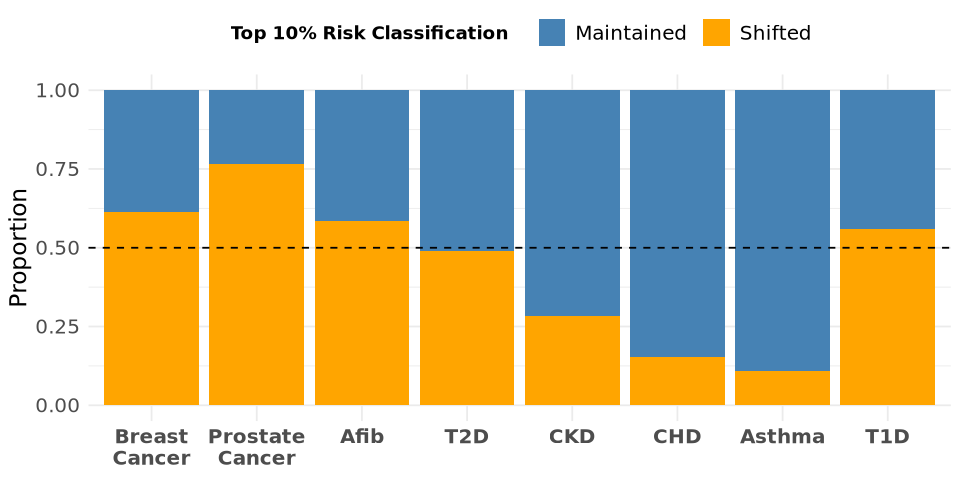

In [18]:
options(repr.plot.width = 8, repr.plot.height = 4)  # Set width and height

df_plot <- results %>%
  mutate(
    `Maintained ` = overlap_top,
    Shifted = (n_top_ten - overlap_top) * 2
  ) %>%
  select(Disease, `Maintained `, Shifted, percent_diff_prev)


df_long <- df_plot %>%
  pivot_longer(cols = c(`Maintained `, Shifted), names_to = "Status", values_to = "Count")

# Map names
df_long <- df_long  %>% mutate(Disease = as.character(Disease), 
                                                    Disease = recode(Disease, 
                                                    !!!disease_name_mapping_short, 
                                                                     .default = Disease) )

facet_order <- c(
  "Breast\nCancer", "Prostate\nCancer", "Afib", "T2D",
  "CKD", "CHD", "Asthma", "T1D"
)

df_long <- df_long %>%
  mutate(
    Disease = factor(Disease, levels = facet_order)
  )


# Plot horizontal 100% stacked bar chart
plot_A <- ggplot(df_long, aes(x = Disease, y = Count, fill = Status)) +
  geom_bar(stat = "identity", position = "fill") +   # 100% stacked
  #coord_flip() +                                     # horizontal bars
  scale_fill_manual(values = c("Maintained " = "steelblue", "Shifted" = "orange")) +
  geom_hline(yintercept = 0.5, linetype = "dashed", color = "black") +  # dashed 50% line
  labs(
    x = NULL, 
    y = "Proportion",
    fill = "Top 10% Risk Classification   ",
    title = NULL
  ) +
  theme_minimal() +
  theme(axis.text.x = element_text(size=12, face= "bold"),
        axis.text.y = element_text(size=12),
        axis.title.y = element_text(size=14),
    strip.text = element_text(size = 12, face = "bold"),
    legend.title = element_text(face = "bold", hjust=.5),
                legend.text = element_text(size=12),
       legend.position = "top")

plot_A

Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


Disease,prev_genetic_top,prev_joint_top,n_top_ten,overlap_top,prop_maintained,prop_changed,percent_diff_prev,percent_changed
<chr>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Asthma,0.952,0.954,1516,1455,95.98,4.02,0.21,0.40
Afib,0.580,0.572,1296,690,53.24,46.76,-1.38,4.68
BreastC,0.187,0.222,3265,1812,55.50,44.50,18.72,4.45
CKD,0.661,0.668,2016,1728,85.71,14.29,1.06,1.43
CHD,0.518,0.517,4999,4651,93.04,6.96,-0.19,0.70
ProstateC,0.607,0.845,491,135,27.49,72.51,39.21,7.26
t2d,0.748,0.769,2660,1853,69.66,30.34,2.81,3.03
t1d,0.096,0.094,1828,1163,63.62,36.38,-2.08,3.64


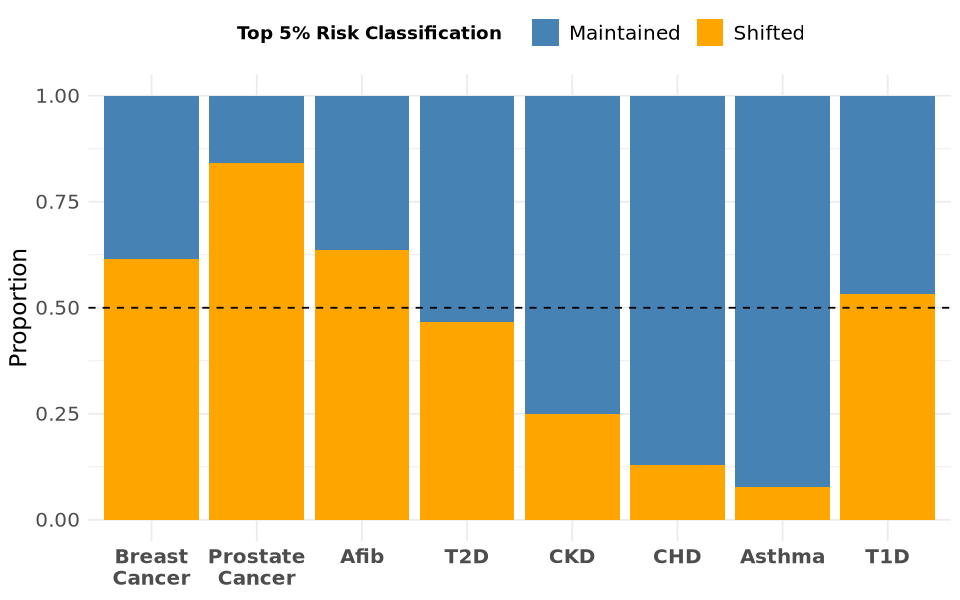

In [19]:
results2 <- map_dfr(diseases, function(disease) {

  fit_and_predict(disease, merged_data) %>%
    flag_top05() %>%
    compare_prevalence(disease)

})

results2 

df_plot <- results2 %>%
  mutate(
    `Maintained ` = overlap_top,
    Shifted = (n_top_ten - overlap_top) * 2
  ) %>%
  select(Disease, `Maintained `, Shifted, percent_diff_prev)


df_long <- df_plot %>%
  pivot_longer(cols = c(`Maintained `, Shifted), names_to = "Status", values_to = "Count")

# Map names
df_long <- df_long  %>% mutate(Disease = as.character(Disease), 
                                                    Disease = recode(Disease, 
                                                    !!!disease_name_mapping_short, 
                                                                     .default = Disease) )

facet_order <- c(
  "Breast\nCancer", "Prostate\nCancer", "Afib", "T2D",
  "CKD", "CHD", "Asthma", "T1D"
)

df_long <- df_long %>%
  mutate(
    Disease = factor(Disease, levels = facet_order)
  )

options(repr.plot.width = 8, repr.plot.height = 5)  # Set width and height


# Plot horizontal 100% stacked bar chart
plot_B <- ggplot(df_long, aes(x = Disease, y = Count, fill = Status)) +
  geom_bar(stat = "identity", position = "fill") +   # 100% stacked
  #coord_flip() +                                     # horizontal bars
  scale_fill_manual(values = c("Maintained " = "steelblue", "Shifted" = "orange")) +
  geom_hline(yintercept = 0.5, linetype = "dashed", color = "black") +  # dashed 50% line
  labs(
    x = NULL, 
    y = "Proportion",
    fill = "Top 5% Risk Classification   ",
    title = NULL
  ) +
  theme_minimal() +
  theme(axis.text.x = element_text(size=12, face= "bold"),
        axis.text.y = element_text(size=12),
        axis.title.y = element_text(size=14),
    strip.text = element_text(size = 12, face = "bold"),
    legend.title = element_text(face = "bold", hjust=.5),
                legend.text = element_text(size=12),
       legend.position = "top")

plot_B

In [20]:
mean(results2$prop_changed)
sd(results2$prop_changed)

[1] 31.97

[1] 23.17827


Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




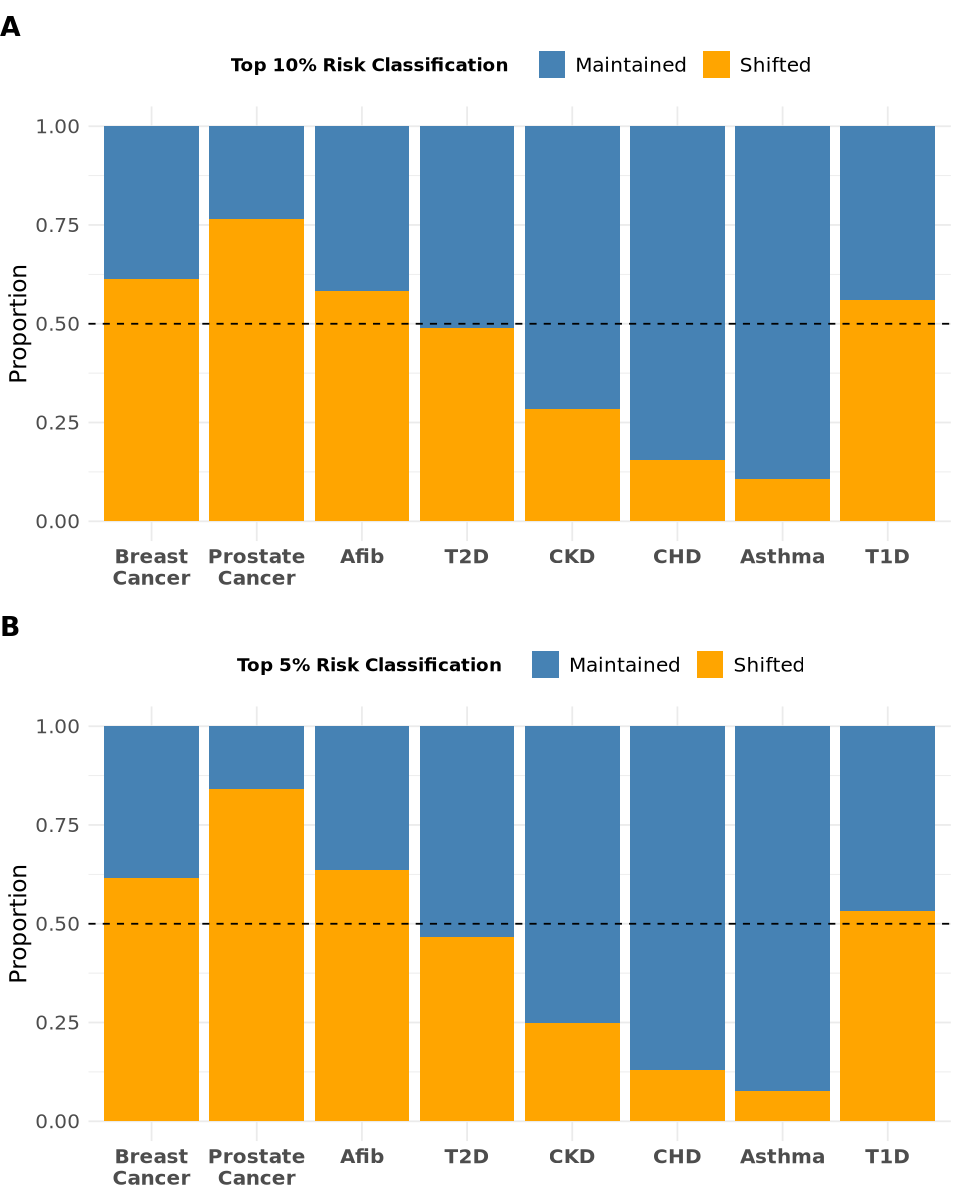

In [21]:
#AB Plot 
library(gridExtra)
library(grid)

options(repr.plot.width = 8, repr.plot.height = 10)  # Set width and height

grid.arrange(
  arrangeGrob(
    plot_A,
    top = textGrob("A", x = unit(0, "npc"), just = c("left", "top"),
                   gp = gpar(fontsize = 16, fontface = "bold"))
  ),
  arrangeGrob(
    plot_B, 
    top = textGrob("B", x = unit(0, "npc"), just = c("left", "top"),
                   gp = gpar(fontsize = 16, fontface = "bold"))
  ),
  ncol = 1
)

## NRI 

In [56]:
# The mcca::nri function accepts user-computed probability matrices with method = "prob".
# Internally, mcca encodes binary classes as 1 and 2, so use 1 = non-case and 2 = case.
make_binary_probability_matrix <- function(p_case) {
  prob_mat <- cbind(`1` = 1 - p_case, `2` = p_case)
  prob_mat <- as.matrix(prob_mat)
  storage.mode(prob_mat) <- "double"
  prob_mat
}

make_top_risk_label <- function(p_case, percentile) {
  if_else(
    p_case >= quantile(p_case, percentile, na.rm = TRUE),
    2L,
    1L
  )
}

run_mcca_nri <- function(y, m1, m2, method) {
  tryCatch(
    suppressWarnings(as.numeric(mcca::nri(y = y, m1 = m1, m2 = m2, method = method))),
    error = function(e) NA_real_
  )
}

calculate_nri_values <- function(pred_df, disease, reference_pred_col, new_pred_col) {

  # mcca expects class labels encoded as 1, 2, ..., k.
  # Use 1 for controls/non-cases and 2 for cases.
  y_mcca <- if_else(pred_df[[disease]] == 1, 2L, 1L)

  # Bootstrap samples occasionally contain only one class for rare outcomes.
  if (length(unique(y_mcca)) < 2) {
    return(tibble(
      nri_probability = NA_real_,
      nri_top10 = NA_real_,
      nri_top05 = NA_real_
    ))
  }

  reference_prob <- make_binary_probability_matrix(pred_df[[reference_pred_col]])
  new_prob       <- make_binary_probability_matrix(pred_df[[new_pred_col]])

  reference_top10 <- make_top_risk_label(pred_df[[reference_pred_col]], 0.90)
  new_top10       <- make_top_risk_label(pred_df[[new_pred_col]], 0.90)

  reference_top05 <- make_top_risk_label(pred_df[[reference_pred_col]], 0.95)
  new_top05       <- make_top_risk_label(pred_df[[new_pred_col]], 0.95)

  tibble(
    nri_probability = run_mcca_nri(
      y = y_mcca,
      m1 = reference_prob,
      m2 = new_prob,
      method = "prob"
    ),
    nri_top10 = run_mcca_nri(
      y = y_mcca,
      m1 = reference_top10,
      m2 = new_top10,
      method = "label"
    ),
    nri_top05 = run_mcca_nri(
      y = y_mcca,
      m1 = reference_top05,
      m2 = new_top05,
      method = "label"
    )
  )
}

bootstrap_nri_ci <- function(
  pred_df,
  disease,
  reference_pred_col,
  new_pred_col,
  n_boot = 100,
  conf_level = 0.95
) {

  alpha <- 1 - conf_level
  n <- nrow(pred_df)

  boot_estimates <- map_dfr(seq_len(n_boot), function(i) {
    boot_idx <- sample.int(n, size = n, replace = TRUE)
    calculate_nri_values(
      pred_df = pred_df[boot_idx, , drop = FALSE],
      disease = disease,
      reference_pred_col = reference_pred_col,
      new_pred_col = new_pred_col
    )
  })

  summarise(
    boot_estimates,
    nri_probability_ci_lower = quantile(nri_probability, alpha / 2, na.rm = TRUE),
    nri_probability_ci_upper = quantile(nri_probability, 1 - alpha / 2, na.rm = TRUE),
    nri_top10_ci_lower = quantile(nri_top10, alpha / 2, na.rm = TRUE),
    nri_top10_ci_upper = quantile(nri_top10, 1 - alpha / 2, na.rm = TRUE),
    nri_top05_ci_lower = quantile(nri_top05, alpha / 2, na.rm = TRUE),
    nri_top05_ci_upper = quantile(nri_top05, 1 - alpha / 2, na.rm = TRUE),
    n_boot = n_boot,
    n_boot_valid_probability = sum(!is.na(nri_probability)),
    n_boot_valid_top10 = sum(!is.na(nri_top10)),
    n_boot_valid_top05 = sum(!is.na(nri_top05))
  )
}

calculate_nri_for_model_pair <- function(
  disease,
  data,
  reference_pred_col,
  new_pred_col,
  reference_model,
  new_model,
  n_boot = 100,
  conf_level = 0.95
) {

  pred_df <- fit_and_predict(disease, data) %>%
    filter(
      !is.na(.data[[disease]]),
      !is.na(.data[[reference_pred_col]]),
      !is.na(.data[[new_pred_col]])
    )

  point_estimates <- calculate_nri_values(
    pred_df = pred_df,
    disease = disease,
    reference_pred_col = reference_pred_col,
    new_pred_col = new_pred_col
  )

  ci_estimates <- bootstrap_nri_ci(
    pred_df = pred_df,
    disease = disease,
    reference_pred_col = reference_pred_col,
    new_pred_col = new_pred_col,
    n_boot = n_boot,
    conf_level = conf_level
  )

  tibble(
    Disease = disease,
    comparison = paste(reference_model, "to", new_model),
    reference_model = reference_model,
    new_model = new_model,
    n = nrow(pred_df),
    cases = sum(pred_df[[disease]] == 1, na.rm = TRUE),
    controls = sum(pred_df[[disease]] == 0, na.rm = TRUE)
  ) %>%
    bind_cols(point_estimates, ci_estimates)
}


n_boot_nri <- 100 # Increase n_boot_nri for final analyses if runtime allows
set.seed(42)

nri_results <- map_dfr(diseases, function(disease) {
  bind_rows(
    calculate_nri_for_model_pair(
      disease = disease,
      data = merged_data,
      reference_pred_col = "pred_base",
      new_pred_col = "pred_genetic",
      reference_model = "Base",
      new_model = "Genetic",
      n_boot = n_boot_nri
    ),
    calculate_nri_for_model_pair(
      disease = disease,
      data = merged_data,
      reference_pred_col = "pred_genetic",
      new_pred_col = "pred_joint",
      reference_model = "Genetic",
      new_model = "Joint",
      n_boot = n_boot_nri
    ),
    calculate_nri_for_model_pair(
      disease = disease,
      data = merged_data,
      reference_pred_col = "pred_base",
      new_pred_col = "pred_joint",
      reference_model = "Base",
      new_model = "Joint",
      n_boot = n_boot_nri
    )  
  )
}) %>%
  mutate(
    Disease_label = recode(as.character(Disease), !!!disease_name_mapping, .default = as.character(Disease))
  ) %>%
  relocate(Disease_label, .after = Disease)

nri_results

write_excel_csv(nri_results, file.path(output_dir, "nri_results.csv"))


Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


Disease,Disease_label,comparison,reference_model,new_model,n,cases,controls,nri_probability,nri_top10,⋯,nri_probability_ci_lower,nri_probability_ci_upper,nri_top10_ci_lower,nri_top10_ci_upper,nri_top05_ci_lower,nri_top05_ci_upper,n_boot,n_boot_valid_probability,n_boot_valid_top10,n_boot_valid_top05
<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>
Asthma,Asthma,Base to Genetic,Base,Genetic,30320,12315,18005,3.001319e-03,0.0006596306,⋯,8.525726e-04,5.147592e-03,2.968338e-05,0.001353892,-1.978892e-04,0.0004617414,100,100,100,100
Asthma,Asthma,Genetic to Joint,Genetic,Joint,30320,12315,18005,1.223615e-02,0.0031662269,⋯,9.591029e-03,1.451352e-02,2.241095e-03,0.004093008,-6.761214e-05,0.0005953166,100,100,100,100
Asthma,Asthma,Base to Joint,Base,Joint,30320,12315,18005,1.523747e-02,0.0038258575,⋯,1.222873e-02,1.740023e-02,2.621207e-03,0.004898582,-3.463061e-05,0.0008921504,100,100,100,100
Afib,Atrial Fibrilation (Afib),Base to Genetic,Base,Genetic,25907,8222,17685,9.032308e-03,0.0085691126,⋯,6.155672e-03,1.158181e-02,5.264021e-03,0.013269580,4.205427e-03,0.0109622882,100,100,100,100
Afib,Atrial Fibrilation (Afib),Genetic to Joint,Genetic,Joint,25907,8222,17685,2.817771e-03,0.0052495465,⋯,-7.719921e-06,6.331300e-03,1.857606e-03,0.008231366,-3.225962e-03,0.0021490331,100,100,100,100
Afib,Atrial Fibrilation (Afib),Base to Joint,Base,Joint,25907,8222,17685,1.185008e-02,0.0138186590,⋯,7.629212e-03,1.496217e-02,9.963523e-03,0.017759679,3.723897e-03,0.0091317019,100,100,100,100
BreastC,Breast Cancer,Base to Genetic,Base,Genetic,65287,5324,59963,1.072189e-04,0.0007045813,⋯,-3.867539e-05,2.224792e-04,-4.522340e-04,0.002067793,3.829246e-04,0.0023442646,100,100,100,100
BreastC,Breast Cancer,Genetic to Joint,Genetic,Joint,65287,5324,59963,0.000000e+00,0.0041968539,⋯,-1.458943e-04,1.233017e-04,2.523473e-03,0.005698684,2.136336e-03,0.0045361251,100,100,100,100
BreastC,Breast Cancer,Base to Joint,Base,Joint,65287,5324,59963,1.072189e-04,0.0049014352,⋯,-8.462634e-05,2.917886e-04,3.383522e-03,0.006918682,3.627828e-03,0.0061145404,100,100,100,100


In [ ]:
nri_plot_df <- nri_results %>%
  filter(comparison != "Genetic to Joint") |>
  mutate(
    Disease_short = recode(as.character(Disease), !!!disease_name_mapping_short, .default = as.character(Disease)),
    Disease_short = factor(Disease_short, levels = rev(facet_order)),
    comparison_label = recode(
      as.character(comparison),
      "Base to Joint" = "Base + PRS + PsRS",
        "Base to Genetic" = "Base + PRS"),
     comparison_label = factor(comparison_label, levels = c("Base + PRS + PsRS", "Base + PRS")
    )
  )

comparison_colors <- c(
  "Base + PRS" = "#2C7FB8",
  "Base + PRS + PsRS" = "#F28E2B"
)

# 1) Full probability-based NRI: how much each model increment improves classification.
plot_nri_probability_df <- nri_plot_df %>%
  mutate(
    nri_percent = 100 * nri_probability,
    nri_ci_lower_percent = 100 * nri_probability_ci_lower,
    nri_ci_upper_percent = 100 * nri_probability_ci_upper,
    value_hjust = if_else(nri_percent >= 0, -0.12, 1.12)
  )

plot_nri_probability <- plot_nri_probability_df %>%
  ggplot(aes(x = nri_percent, y = Disease_short, fill = comparison_label)) +
  geom_vline(xintercept = 0, linewidth = 0.4, color = "grey35") +
  geom_col(position = position_dodge(width = 0.72), width = 0.62) +
  geom_errorbarh(
    aes(xmin = nri_ci_lower_percent, xmax = nri_ci_upper_percent),
    position = position_dodge(width = 0.72),
    height = 0.18,
    linewidth = 0.45,
    color = "grey20"
  ) +
  scale_fill_manual(values = comparison_colors) +
  scale_x_continuous(expand = expansion(mult = c(0.08, 0.18))) +
  labs(
    x = "NRI, percentage points",
    y = NULL,
    fill = NULL,
    title = "NRI probability"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    legend.position = "top",
    panel.grid.major.y = element_blank(),
    axis.text.y = element_text(face = "bold"),
    plot.title = element_text(face = "bold")
  )

ggsave(
  filename = file.path(output_dir, "plot_nri_probability_comparison.png"),
  plot = plot_nri_probability,
  width = 9,
  height = 5.8,
  dpi = 300
)

# 2) Top-risk NRI: whether movement into/out of the highest-risk strata helped classification.
nri_toprisk_long <- nri_plot_df %>%
  select(Disease_short, comparison_label, nri_top10, nri_top05) %>%
  pivot_longer(
    cols = c(nri_top10, nri_top05),
    names_to = "top_risk_definition",
    values_to = "nri"
  ) %>%
  mutate(
    top_risk_definition = recode(
      top_risk_definition,
      "nri_top10" = "Top 10% risk group",
      "nri_top05" = "Top 5% risk group"
    ),
    top_risk_definition = factor(top_risk_definition, levels = c("Top 10% risk group", "Top 5% risk group")),
    nri_percent = 100 * nri
  )


# 4) Threshold-specific bar plots for the top 10% and top 5% risk groups.
plot_nri_threshold_bar <- function(plot_df, threshold_col, threshold_label, output_file) {

  threshold_df <- plot_df %>%
    mutate(
      nri_percent = 100 * .data[[threshold_col]],
      nri_ci_lower_percent = 100 * .data[[paste0(threshold_col, "_ci_lower")]],
      nri_ci_upper_percent = 100 * .data[[paste0(threshold_col, "_ci_upper")]],
      value_label = sprintf("%.2f", nri_percent),
      value_hjust = if_else(nri_percent >= 0, -0.5, 1.5)
    )

  p <- threshold_df %>%
    ggplot(aes(x = nri_percent, y = Disease_short, fill = comparison_label)) +
    geom_vline(xintercept = 0, linewidth = 0.4, color = "grey35") +
    geom_col(position = position_dodge(width = 0.72), width = 0.62) +
    geom_errorbarh(
      aes(xmin = nri_ci_lower_percent, xmax = nri_ci_upper_percent),
      position = position_dodge(width = 0.72),
      height = 0.18,
      linewidth = 0.45,
      color = "grey20"
    ) +
    scale_fill_manual(values = comparison_colors) +
    scale_x_continuous(expand = expansion(mult = c(0.08, 0.20))) +
    labs(
      x = "NRI, percentage points",
      y = NULL,
      fill = NULL,
      title = paste0("NRI ", threshold_label) ) +
    theme_minimal(base_size = 13) +
    theme(
      legend.position = "top",
      panel.grid.major.y = element_blank(),
      axis.text.y = element_text(face = "bold"),
      plot.title = element_text(face = "bold")
    )

  ggsave(
    filename = file.path(output_dir, output_file),
    plot = p,
    width = 9,
    height = 5.8,
    dpi = 300
  )

  p
}

plot_nri_top10_bar <- plot_nri_threshold_bar(
  plot_df = nri_plot_df,
  threshold_col = "nri_top10",
  threshold_label = "top 10%",
  output_file = "plot_nri_top10_bar_comparison.png"
)

plot_nri_top05_bar <- plot_nri_threshold_bar(
  plot_df = nri_plot_df,
  threshold_col = "nri_top05",
  threshold_label = "top 5%",
  output_file = "plot_nri_top05_bar_comparison.png"
)


`height` was
translated to
`width`.
`height` was
translated to
`width`.


In [ ]:
library(patchwork)
options(repr.plot.width = 12, repr.plot.height = 10)

combined_plot <- 
  plot_nri_probability +
  plot_nri_top10_bar +
  plot_nri_top05_bar +
  plot_layout(
    ncol = 3,
    guides = "collect"
  ) +
  plot_annotation( tag_levels = list(c("A.", "B.", "C."))) &
  theme(
    legend.position = "bottom",
    legend.text = element_text(size=16),
    plot.tag = element_text(face = "bold")
  )

combined_plot